In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import sys
print(sys.version)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [3]:
%pip install -U pip setuptools wheel
%pip install -U numpy pandas scikit-learn
%pip install -U lifelines scikit-survival

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 44.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 110.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 55.2 MB/s  0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4119 sha256=8ecc46cbe94b6a0fe057b7752bf45298aab663106295c24d607849f73427fab5
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.9.0
    Uninstalling scikit-learn-1.9.0:
      Successfully uninstalled scikit-learn-1.9.0
  Attempting uninstall: pandas
    Found existing installation: pandas 3.0.4
    Uninstalling pandas-3.0.4:
      Successfully uninstalled pandas-3.0.4
   ━━━

In [4]:
import os
import json
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

import matplotlib.pyplot as plt
import seaborn as sns

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index

from sksurv.util import Surv
from sksurv.metrics import integrated_brier_score, cumulative_dynamic_auc

In [5]:
PROCESSED_DATA_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/"
UNICOX_OUTPUT_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/UnivariateCox/"
RESULTS_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/"
MODEL_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/UnivariateCox/"

os.makedirs(UNICOX_OUTPUT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

TRAIN_PATH = UNICOX_OUTPUT_DIR + "hcc_UniCox_train_selected.csv"
TEST_PATH = UNICOX_OUTPUT_DIR + "hcc_UniCox_test_selected.csv"
MODEL_PATH = MODEL_DIR + "hcc_UniCox_deepsurv_model.pth"

PREDICTION_OUTPUT_PATH = RESULTS_DIR + "hcc_UniCox_deepsurv_test_predictions.csv"
METRICS_PATH = RESULTS_DIR + "hcc_UniCox_deepsurv_metrics.csv"
KM_PLOT_PATH = RESULTS_DIR + "hcc_UniCox_deepsurv_km_risk_groups.png"
RISK_HIST_PATH = RESULTS_DIR + "hcc_UniCox_deepsurv_risk_histogram.png"
ORDERED_RISK_PATH = RESULTS_DIR + "hcc_UniCox_deepsurv_ordered_risk_scores.png"
SURVIVAL_CURVE_PLOT_PATH = RESULTS_DIR + "hcc_UniCox_deepsurv_example_survival_curves.png"

DURATION_COL = "OS_MONTHS"
EVENT_COL = "OS_EVENT"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [6]:
train_data = pd.read_csv(TRAIN_PATH)
test_data = pd.read_csv(TEST_PATH)

print("Train data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

test_data.head()

Train data shape: (1085, 52)
Test data shape: (272, 52)


,METASTASIS_Yes,CURATIVE_INTENT_SURGERY_Yes,CURATIVE_INTENT_SURGERY_No,METASTASIS_No,MAJOR_LIVER_RESECTION_,RESECTION_MARGIN_,RESECTION_MARGIN_R0,C_N_Yes,PNI_,LVI_,...,TUMOR_STAGE_Poorly differentiated,TUMOR_STAGE_Well differentiated,MUT_SHQ1,CNA_XPO1,CNA_REL,MUT_KRAS,NEOADJUVANT_SYSTEMIC_THERAPY_No,MUT_FGFR4,OS_MONTHS,OS_EVENT
0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,28.980,1
1,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,5.952,1
2,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.984,0
3,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,23.652,1
4,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,36.696,0


In [7]:
print("Train missing values:", int(train_data.isna().sum().sum()))
print("Test missing values:", int(test_data.isna().sum().sum()))

print("\nTrain OS_EVENT distribution:")
print(train_data[EVENT_COL].value_counts())

print("\nTest OS_EVENT distribution:")
print(test_data[EVENT_COL].value_counts())

Train missing values: 0
Test missing values: 0

Train OS_EVENT distribution:
OS_EVENT
1    641
0    444
Name: count, dtype: int64

Test OS_EVENT distribution:
OS_EVENT
1    161
0    111
Name: count, dtype: int64


In [8]:
for id_col in ["PATIENT_ID", "SAMPLE_ID"]:
    assert id_col not in train_data.columns, f"{id_col} found in train_data"
    assert id_col not in test_data.columns, f"{id_col} found in test_data"

print("ID leakage guard passed.")

ID leakage guard passed.


In [9]:
class DeepSurv(nn.Module):
    def __init__(self, input_dim, hidden_layers, dropout_rate, activation_name):
        super(DeepSurv, self).__init__()

        activation_map = {
            "ReLU": nn.ReLU,
            "LeakyReLU": nn.LeakyReLU,
            "ELU": nn.ELU,
            "SELU": nn.SELU
        }

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(activation_map[activation_name]())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            current_dim = hidden_dim

        self.feature_extractor = nn.Sequential(*layers)
        self.output_layer = nn.Linear(current_dim, 1)

    def forward(self, x):
        x = self.feature_extractor(x)
        return self.output_layer(x)

In [10]:
checkpoint = torch.load(MODEL_PATH, map_location=DEVICE)

INPUT_DIM = checkpoint["input_dim"]
HIDDEN_LAYERS = checkpoint["hidden_layers"]
DROPOUT_RATE = checkpoint["dropout_rate"]
ACTIVATION = checkpoint["activation"]
GENES = checkpoint["feature_columns"]

print("Input dimension:", INPUT_DIM)
print("Hidden layers:", HIDDEN_LAYERS)
print("Dropout rate:", DROPOUT_RATE)
print("Activation:", ACTIVATION)
print("Feature count:", len(GENES))

Input dimension: 50
Hidden layers: [128, 64]
Dropout rate: 0.2
Activation: ReLU
Feature count: 50


In [11]:
model = DeepSurv(
    input_dim=INPUT_DIM,
    hidden_layers=HIDDEN_LAYERS,
    dropout_rate=DROPOUT_RATE,
    activation_name=ACTIVATION
).to(DEVICE)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Model loaded successfully")

Model loaded successfully


In [12]:
X_train = train_data[GENES].copy()
y_train = train_data[[DURATION_COL, EVENT_COL]].copy()

X_test = test_data[GENES].copy()
y_test = test_data[[DURATION_COL, EVENT_COL]].copy()

print("Train feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)

Train feature shape: (1085, 50)
Test feature shape: (272, 50)


In [13]:
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32).to(DEVICE)

with torch.no_grad():
    test_preds = model(X_test_tensor).cpu().numpy().reshape(-1)

test_c_index = concordance_index(
    y_test[DURATION_COL].values,
    -test_preds,
    y_test[EVENT_COL].values
)

print(f"Test Concordance Index: {test_c_index:.4f}")

Test Concordance Index: 0.7222


In [14]:
evaluation_df = test_data[[DURATION_COL, EVENT_COL]].copy()
evaluation_df["risk_score"] = test_preds

print("Evaluation dataframe shape:", evaluation_df.shape)
evaluation_df.head()

Evaluation dataframe shape: (272, 3)


,OS_MONTHS,OS_EVENT,risk_score
0,28.980,1,-0.240907
1,5.952,1,1.085288
2,9.984,0,1.007651
3,23.652,1,1.135491
4,36.696,0,-0.576507


In [15]:
y_train_sksurv = Surv.from_dataframe(EVENT_COL, DURATION_COL, train_data)
y_test_sksurv = Surv.from_dataframe(EVENT_COL, DURATION_COL, test_data)

In [16]:
def compute_baseline_survival(model, X_train, durations_train, events_train):
    X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32).to(DEVICE)

    with torch.no_grad():
        train_risk_scores = model(X_train_tensor).cpu().numpy().reshape(-1)

    unique_event_times = np.sort(np.unique(durations_train[events_train == 1]))
    cumulative_hazard = []
    running_hazard = 0.0

    for time_point in unique_event_times:
        events_at_time = np.sum((durations_train == time_point) & (events_train == 1))
        at_risk_mask = durations_train >= time_point
        risk_sum = np.sum(np.exp(train_risk_scores[at_risk_mask]))

        running_hazard += events_at_time / risk_sum
        cumulative_hazard.append(running_hazard)

    baseline_survival = np.exp(-np.array(cumulative_hazard))
    return unique_event_times, baseline_survival

In [17]:
def predict_survival_curves(model, X_input, event_times, baseline_survival):
    X_input_tensor = torch.tensor(X_input.values, dtype=torch.float32).to(DEVICE)

    with torch.no_grad():
        risk_scores = model(X_input_tensor).cpu().numpy().reshape(-1)

    survival_curves = []

    for risk_score in risk_scores:
        hazard_ratio = np.exp(risk_score)
        patient_survival = baseline_survival ** hazard_ratio
        survival_curves.append(patient_survival)

    return np.array(survival_curves)

In [18]:
event_times, baseline_survival = compute_baseline_survival(
    model,
    X_train,
    y_train[DURATION_COL].values,
    y_train[EVENT_COL].values
)

survival_curves = predict_survival_curves(
    model,
    X_test,
    event_times,
    baseline_survival
)

print("Number of baseline event times:", len(event_times))
print("Survival curve matrix shape:", survival_curves.shape)

Number of baseline event times: 519
Survival curve matrix shape: (272, 519)


In [19]:
requested_time_points = np.array([1, 3, 5]) * 12
max_eval_time = min(train_data[DURATION_COL].max(), test_data[DURATION_COL].max())

time_points = requested_time_points[requested_time_points < max_eval_time]

if len(time_points) == 0:
    raise ValueError("No valid AUC time points are within observed follow-up range.")

print("AUC time points used (months):", time_points)

AUC time points used (months): [12 36 60]


In [20]:
valid_time_mask = (event_times >= 1) & (event_times < max_eval_time)
time_grid = event_times[valid_time_mask]
surv_probs = survival_curves[:, valid_time_mask]

if len(time_grid) == 0:
    raise ValueError("Time grid for IBS is empty. Check survival follow-up range.")

print("IBS time grid length:", len(time_grid))
print("Survival probability matrix shape:", surv_probs.shape)

IBS time grid length: 516
Survival probability matrix shape: (272, 516)


In [21]:
ibs = integrated_brier_score(y_train_sksurv, y_test_sksurv, surv_probs, time_grid)
print(f"Integrated Brier Score: {ibs:.4f}")

Integrated Brier Score: 0.1409


In [22]:
auc_scores, mean_auc = cumulative_dynamic_auc(
    y_train_sksurv,
    y_test_sksurv,
    test_preds,
    time_points
)

for t, auc in zip(time_points, auc_scores):
    print(f"AUC at {int(t/12)} years: {auc:.4f}")

print(f"Mean time-dependent AUC: {mean_auc:.4f}")

AUC at 1 years: 0.8019
AUC at 3 years: 0.8022
AUC at 5 years: 0.8034
Mean time-dependent AUC: 0.8024


In [23]:
median_risk = evaluation_df["risk_score"].median()

evaluation_df["risk_group"] = evaluation_df["risk_score"].apply(
    lambda x: "High risk" if x >= median_risk else "Low risk"
)

evaluation_df["risk_group"].value_counts()

,count
risk_group,
Low risk,136
High risk,136


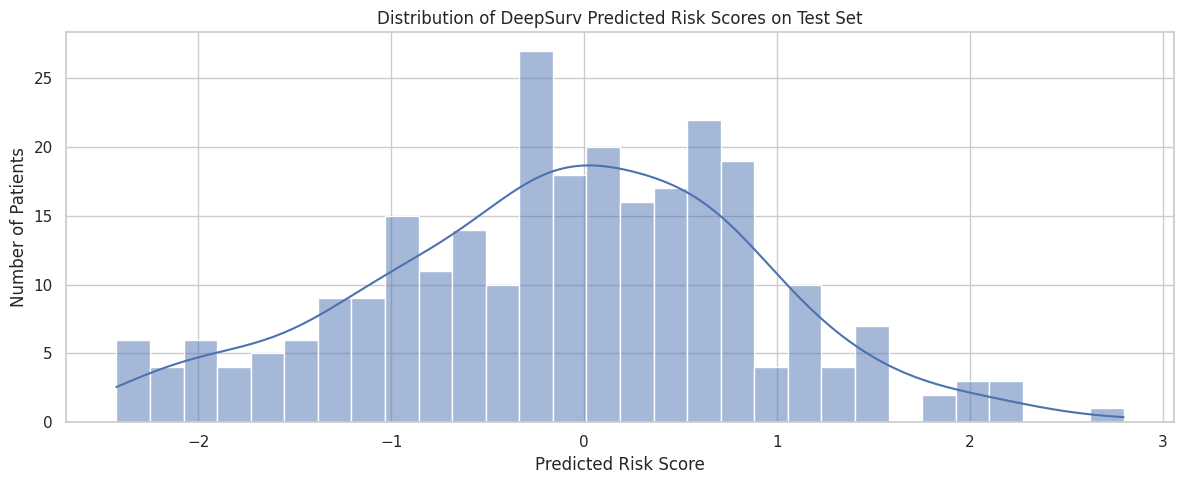

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/hcc_UniCox_deepsurv_risk_histogram.png'

In [24]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))
sns.histplot(evaluation_df["risk_score"], bins=30, kde=True)
plt.title("Distribution of DeepSurv Predicted Risk Scores on Test Set")
plt.xlabel("Predicted Risk Score")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.savefig(RISK_HIST_PATH, dpi=300, bbox_inches="tight")
plt.show()

RISK_HIST_PATH

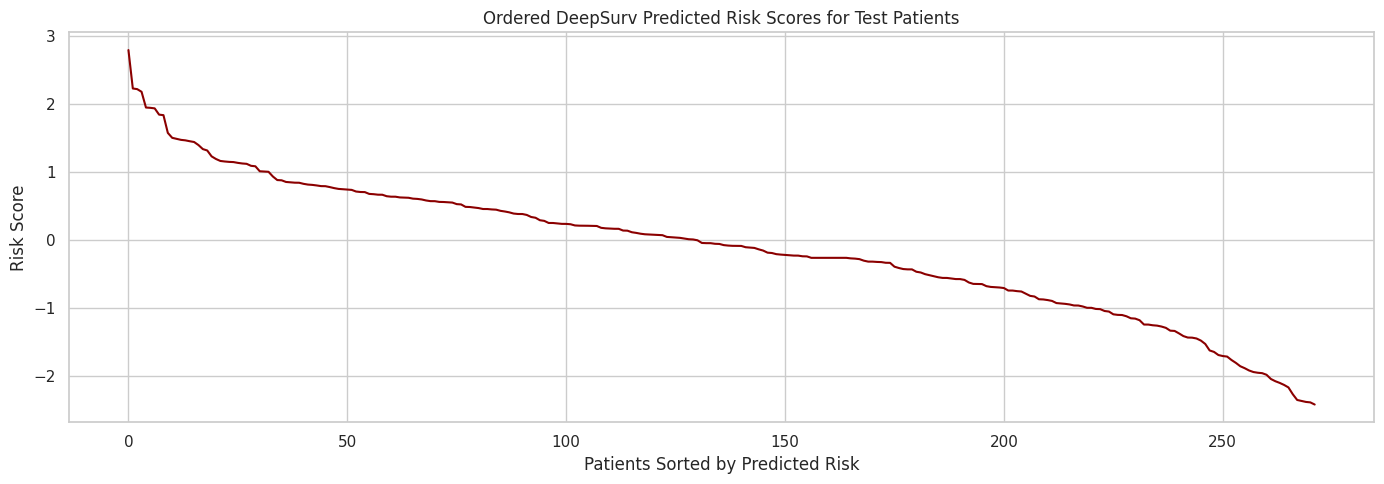

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/hcc_UniCox_deepsurv_ordered_risk_scores.png'

In [25]:
evaluation_df_sorted = evaluation_df.sort_values("risk_score", ascending=False).reset_index(drop=True)

plt.figure(figsize=(14, 5))
plt.plot(evaluation_df_sorted["risk_score"].values, color="darkred")
plt.title("Ordered DeepSurv Predicted Risk Scores for Test Patients")
plt.xlabel("Patients Sorted by Predicted Risk")
plt.ylabel("Risk Score")
plt.tight_layout()
plt.savefig(ORDERED_RISK_PATH, dpi=300, bbox_inches="tight")
plt.show()

ORDERED_RISK_PATH

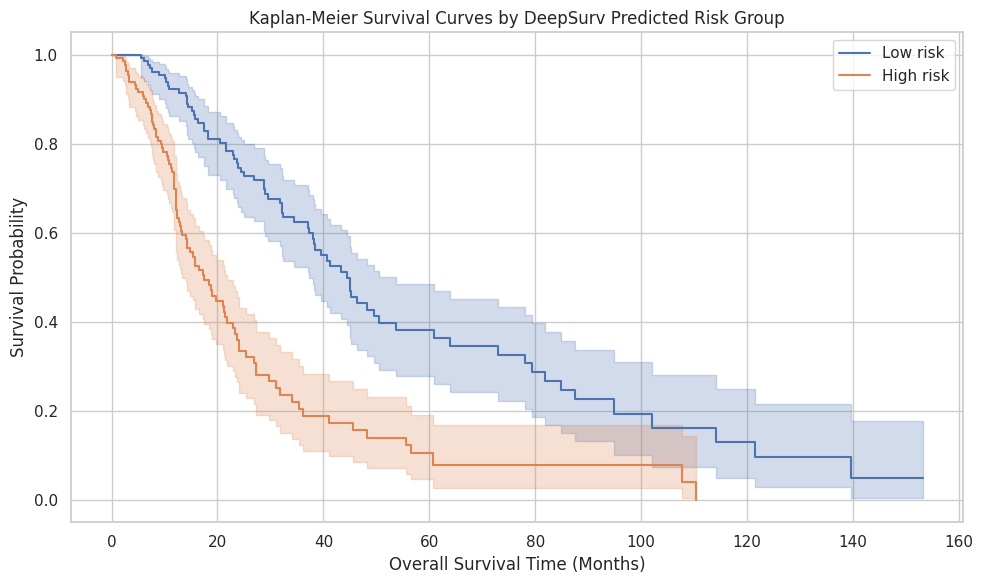

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/hcc_UniCox_deepsurv_km_risk_groups.png'

In [26]:
kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for group_name in ["Low risk", "High risk"]:
    group_df = evaluation_df[evaluation_df["risk_group"] == group_name]

    kmf.fit(
        durations=group_df[DURATION_COL],
        event_observed=group_df[EVENT_COL],
        label=group_name
    )
    kmf.plot_survival_function(ci_show=True)

plt.title("Kaplan-Meier Survival Curves by DeepSurv Predicted Risk Group")
plt.xlabel("Overall Survival Time (Months)")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.tight_layout()
plt.savefig(KM_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

KM_PLOT_PATH

In [27]:
low_risk_df = evaluation_df[evaluation_df["risk_group"] == "Low risk"]
high_risk_df = evaluation_df[evaluation_df["risk_group"] == "High risk"]

logrank_result = logrank_test(
    low_risk_df[DURATION_COL],
    high_risk_df[DURATION_COL],
    event_observed_A=low_risk_df[EVENT_COL],
    event_observed_B=high_risk_df[EVENT_COL]
)

print("Log-rank test p-value:", logrank_result.p_value)

Log-rank test p-value: 6.216948003877547e-11


In [28]:
selected_times = [12, 24, 36, 60]

for month in selected_times:
    closest_index = np.argmin(np.abs(event_times - month))
    evaluation_df[f"survival_prob_{month}m"] = survival_curves[:, closest_index]

evaluation_df.head()

,OS_MONTHS,OS_EVENT,risk_score,risk_group,survival_prob_12m,survival_prob_24m,survival_prob_36m,survival_prob_60m
0,28.980,1,-0.240907,Low risk,0.842426,0.609148,0.407166,0.169925
1,5.952,1,1.085288,High risk,0.524206,0.154568,0.033895,0.001261
2,9.984,0,1.007651,High risk,0.550117,0.177701,0.043644,0.002076
3,23.652,1,1.135491,High risk,0.507061,0.140401,0.028474,0.000894
4,36.696,0,-0.576507,Low risk,0.884631,0.701611,0.526044,0.281646


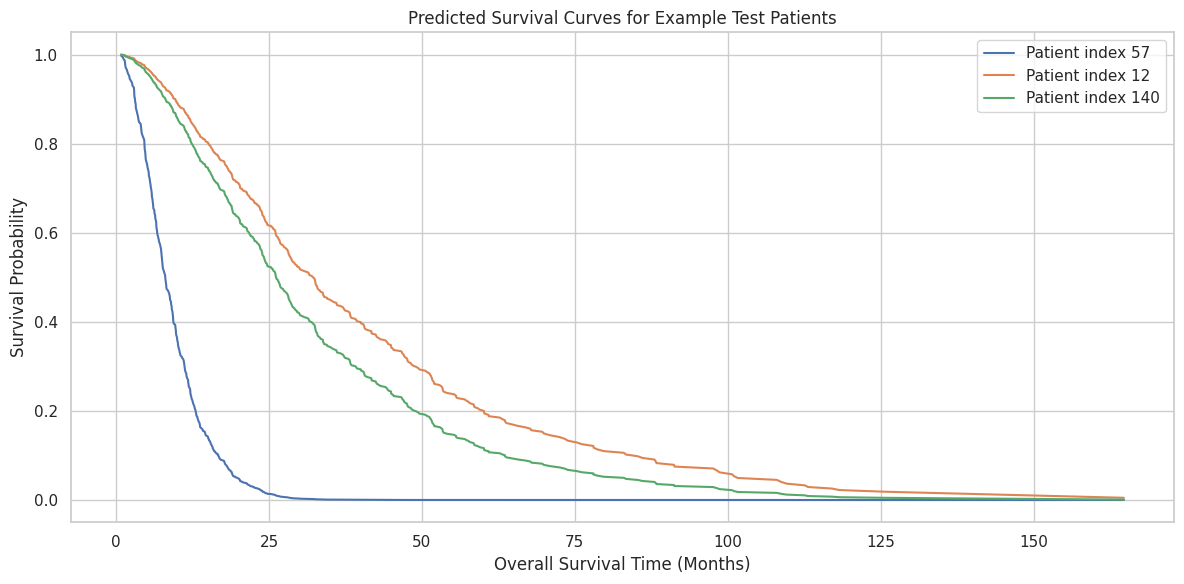

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/hcc_UniCox_deepsurv_example_survival_curves.png'

In [29]:
import random

random.seed(42)
example_patients = random.sample(range(len(test_data)), 3)

plt.figure(figsize=(12, 6))

for patient_index in example_patients:
    plt.plot(
        event_times,
        survival_curves[patient_index],
        label=f"Patient index {patient_index}"
    )

plt.title("Predicted Survival Curves for Example Test Patients")
plt.xlabel("Overall Survival Time (Months)")
plt.ylabel("Survival Probability")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(SURVIVAL_CURVE_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

SURVIVAL_CURVE_PLOT_PATH

In [30]:
evaluation_df.to_csv(PREDICTION_OUTPUT_PATH, index=False)

print("Saved predictions to:", PREDICTION_OUTPUT_PATH)

Saved predictions to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/hcc_UniCox_deepsurv_test_predictions.csv


In [31]:
metrics_rows = [
    {"metric": "C-index", "value": test_c_index},
    {"metric": "IBS", "value": ibs}
]

for t, auc in zip(time_points, auc_scores):
    metrics_rows.append({
        "metric": f"AUC_{int(t/12)}_year",
        "value": auc
    })

metrics_rows.append({"metric": "Mean_time_dependent_AUC", "value": mean_auc})
metrics_rows.append({"metric": "Log-rank_p_value", "value": logrank_result.p_value})

metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(METRICS_PATH, index=False)

metrics_df

,metric,value
0,C-index,7.222351e-01
1,IBS,1.409458e-01
2,AUC_1_year,8.019307e-01
3,AUC_3_year,8.022004e-01
4,AUC_5_year,8.033510e-01
5,Mean_time_dependent_AUC,8.024100e-01
6,Log-rank_p_value,6.216948e-11


In [32]:
PREDICTION_OUTPUT_PATH, METRICS_PATH

('/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/hcc_UniCox_deepsurv_test_predictions.csv',
 '/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/hcc_UniCox_deepsurv_metrics.csv')

**UnivariateCox DeepSurv Evaluation Summary**

The updated UnivariateCox DeepSurv model has now been evaluated on the held-out test set. This evaluation uses the final saved DeepSurv model trained with the optimized hyperparameters from cross-validation:

| Component | Value |
|---|---|
| Feature set | Updated UnivariateCox selected features |
| Model | DeepSurv |
| Hidden layers | `[128, 64]` |
| Dropout | `0.2` |
| Batch size | `128` |
| Activation | `ReLU` |
| Optimizer | `Adam` |
| Weight decay | `0.0001` |
| Learning rate | `0.005` |
| Patience | `20` |
| Epochs | `75` |
| Training C-index | `0.7806` |
| Mean validation C-index | `0.7465` |

The evaluation notebook tested whether this optimized nonlinear survival model generalizes to unseen patients and whether its predicted risk scores meaningfully separate patients into survival-risk groups.

**Evaluation Metrics**

| Metric | Value |
|---|---:|
| Test C-index | `0.7222` |
| Integrated Brier Score | `0.1409` |
| AUC at 1 year | `0.8019` |
| AUC at 3 years | `0.8022` |
| AUC at 5 years | `0.8034` |
| Mean time-dependent AUC | `0.8024` |
| Log-rank p-value | `6.2169e-11` |

**C-index Interpretation**

The test C-index was `0.7222`.

This means that among comparable test-patient pairs, the DeepSurv model correctly ranked the patient with worse survival as higher risk approximately 72.2% of the time.

This is a useful and clinically meaningful discrimination level, but it is lower than the cross-validation mean C-index of `0.7465` and lower than the final training C-index of `0.7806`.

| Stage | C-index |
|---|---:|
| Training | `0.7806` |
| Cross-validation mean | `0.7465` |
| Held-out test | `0.7222` |

This pattern shows expected generalization loss. The model learned strong signal on the training set, performed well during validation, but was less strong on the held-out test set. The drop is not extreme, but it suggests some overfitting or dataset shift between training and test patients.

**Integrated Brier Score Interpretation**

The Integrated Brier Score was `0.1409`.

IBS measures survival probability prediction error over time. Lower values are better. A value of `0.1409` suggests that the model’s survival probability estimates are usable but not as well calibrated as some CoxPH models from the project.

In practical terms, DeepSurv can rank patients reasonably well, but its absolute survival probability estimates may be less accurate. This matters because DeepSurv is strongest as a relative-risk model, while IBS evaluates time-dependent probability accuracy.

**Time-Dependent AUC Interpretation**

The model showed very consistent AUC across all three time horizons:

| Time Point | AUC |
|---|---:|
| 1 year | `0.8019` |
| 3 years | `0.8022` |
| 5 years | `0.8034` |

The mean time-dependent AUC was `0.8024`.

This is one of the most encouraging parts of the evaluation. Unlike some models where performance drops noticeably at later time points, this DeepSurv model maintained stable discrimination from 1 to 5 years.

This means the model is not only useful for short-term survival discrimination but also maintains predictive separation across longer-term follow-up.

**Kaplan-Meier Risk Group Interpretation**

The Kaplan-Meier plot shows clear separation between DeepSurv-predicted low-risk and high-risk groups.

The high-risk group drops sharply early in follow-up, indicating worse survival probability within the first 20-40 months. The low-risk group declines more gradually and maintains higher survival probability across most of the follow-up period.

The log-rank p-value was:

`6.2169e-11`

This is highly significant. It confirms that the model-derived high-risk and low-risk groups have statistically different survival distributions.

So even though the C-index is moderate, the model’s risk stratification remains meaningful.

**Patient-Level Prediction Example**

The output table shows test patients with their observed survival, event status, DeepSurv risk score, risk group, and predicted survival probabilities at 12, 24, 36, and 60 months.

Example interpretation:

| Patient Row | Risk Score | Risk Group | Survival Pattern |
|---|---:|---|---|
| Row 0 | `-0.2409` | Low risk | Predicted 12-month survival `0.8424`, 60-month survival `0.1699` |
| Row 1 | `1.0853` | High risk | Predicted 12-month survival `0.5242`, 60-month survival `0.0013` |
| Row 2 | `1.0077` | High risk | Predicted 12-month survival `0.5501`, 60-month survival `0.0021` |
| Row 3 | `1.1355` | High risk | Predicted 12-month survival `0.5071`, 60-month survival `0.0009` |
| Row 4 | `-0.5765` | Low risk | Predicted 12-month survival `0.8846`, 60-month survival `0.2816` |

Higher risk scores correspond to much lower predicted survival probabilities, which is expected and confirms that the DeepSurv risk-score direction is functioning correctly.

For example, row 3 has a high risk score of `1.1355` and very low predicted 60-month survival probability of `0.0009`. Row 4 has a low risk score of `-0.5765` and a much higher 60-month survival probability of `0.2816`.

**Comparison With Updated UnivariateCox CoxPH**

The updated UnivariateCox CoxPH model had:

| Metric | Updated CoxPH | Updated DeepSurv |
|---|---:|---:|
| Test C-index | `0.7253` | `0.7222` |
| IBS | `0.1302` | `0.1409` |
| AUC 1 year | `0.7982` | `0.8019` |
| AUC 3 years | `0.8086` | `0.8022` |
| AUC 5 years | `0.7531` | `0.8034` |
| Mean AUC | `0.7927` | `0.8024` |
| Log-rank p-value | `4.2992e-12` | `6.2169e-11` |

The updated CoxPH model slightly outperformed DeepSurv on C-index and IBS. This means CoxPH had marginally better pairwise ranking and better survival probability calibration.

However, DeepSurv performed better on 1-year AUC, 5-year AUC, and mean time-dependent AUC. The biggest DeepSurv advantage is at 5 years, where it achieved `0.8034` compared with CoxPH’s `0.7531`.

So the comparison is nuanced:

| Area | Better Model |
|---|---|
| Overall pairwise ranking | CoxPH, slightly |
| Survival probability error | CoxPH |
| 1-year AUC | DeepSurv |
| 3-year AUC | CoxPH, slightly |
| 5-year AUC | DeepSurv |
| Mean time-dependent AUC | DeepSurv |
| Risk-group separation | Both strong |

**Comparison With Previous UnivariateCox DeepSurv Run**

Earlier UnivariateCox DeepSurv evaluation showed approximately:

| Metric | Previous DeepSurv | Updated DeepSurv |
|---|---:|---:|
| Test C-index | `0.7216` | `0.7222` |
| IBS | `0.1401` | `0.1409` |
| AUC 1 year | `0.7770` | `0.8019` |
| AUC 3 years | `0.8311` | `0.8022` |
| AUC 5 years | `0.8098` | `0.8034` |
| Mean AUC | `0.8125` | `0.8024` |
| Log-rank p-value | `3.4965e-11` | `6.2169e-11` |

The updated model slightly improved C-index and 1-year AUC, but the previous model had better 3-year AUC, 5-year AUC, mean AUC, and slightly better IBS.

This tells us that the updated FDR-based feature selection did not clearly improve DeepSurv test performance overall, even though it improved training-validation C-index.

**Key Observations**

The DeepSurv model achieved meaningful survival discrimination on the held-out test set.

The Kaplan-Meier curves show strong separation between predicted risk groups.

The log-rank p-value confirms that the high-risk and low-risk groups differ significantly.

The time-dependent AUC is stable across 1, 3, and 5 years, which is a major strength.

The test C-index is lower than validation C-index, suggesting some generalization loss.

The IBS is relatively high compared with CoxPH, suggesting survival probability calibration is weaker.

DeepSurv appears better at time-specific discrimination than probability calibration.

**Research Interpretation**

The updated UnivariateCox DeepSurv model is useful, but it does not clearly replace CoxPH as the best overall model.

From a predictive standpoint, CoxPH remains slightly stronger by C-index and IBS. From a time-dependent discrimination standpoint, DeepSurv is competitive and stronger at 5 years.

This is scientifically valuable because it shows that neural survival modeling captures some nonlinear or time-dependent discriminatory signal, but the simpler CoxPH model remains highly competitive and more interpretable.

For the paper, this supports a balanced conclusion:

The classical CoxPH model remains the strongest overall interpretable benchmark.

DeepSurv provides complementary nonlinear survival modeling.

DeepSurv XAI is still valuable because it helps identify genomic and clinical features contributing to neural-network risk predictions.

The survival separation shown by Kaplan-Meier curves validates that DeepSurv risk scores are clinically meaningful even when CoxPH performs slightly better on some metrics.

**Conclusion**

The updated UnivariateCox DeepSurv evaluation confirms that the model generalizes reasonably well to the test set. It achieved a test C-index of `0.7222`, mean time-dependent AUC of `0.8024`, and highly significant risk-group separation with log-rank p-value `6.2169e-11`.

The model is strongest in time-dependent discrimination, especially at 5 years, but weaker than CoxPH in IBS and slightly weaker in overall C-index. Therefore, DeepSurv should be treated as a complementary nonlinear survival model rather than the single best final model. Its greatest value in the project remains its ability to support neural-network explainability and consensus prognostic gene discovery alongside the interpretable CoxPH model.